# Nice Rooms: reviews, scenarios and value

Twelve thousand reviews across eleven scenarios, each with a cause and a recovery action. This notebook reads the distribution, checks that sentiment tracks the stars, and joins perceived value to the rate position.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})


def data_dir() -> Path:
    """The folder holding the JSON Lines files, on Kaggle or beside them."""
    for base in (
        Path("/kaggle/input/nice-rooms-hotel-revenue-rate-intelligence"),
        Path("."),
        Path("data/nice-rooms-kaggle"),
        Path("../data/nice-rooms-kaggle"),
    ):
        if (base / "hotels.jsonl").exists():
            return base
    found = list(Path("/kaggle/input").rglob("hotels.jsonl"))
    if found:
        return found[0].parent
    listing = sorted(str(path) for path in Path("/kaggle/input").rglob("*"))
    raise FileNotFoundError("hotels.jsonl not found; /kaggle/input holds " + repr(listing[:20]))


def load(name: str) -> pd.DataFrame:
    return pd.read_json(data_dir() / name, lines=True)


hotels = load("hotels.jsonl")
rooms = load("room_types.jsonl")
daily = load("daily_market.jsonl")
weekly = load("weekly_performance.jsonl")
decisions = load("rate_decisions.jsonl")
reviews = load("reviews.jsonl")
scenarios = load("review_scenarios.jsonl")

daily["date"] = pd.to_datetime(daily["date"])
weekly["week_start"] = pd.to_datetime(weekly["week_start"])
reviews["review_date"] = pd.to_datetime(reviews["review_date"])
reviews["stay_date"] = pd.to_datetime(reviews["stay_date"])
daily["month"] = daily["date"].dt.to_period("M").astype(str)
weekly["month"] = weekly["week_start"].dt.to_period("M").astype(str)


In [2]:
reviews = reviews.merge(
    daily[["hotel_id", "date", "rate_position"]],
    left_on=["hotel_id", "stay_date"],
    right_on=["hotel_id", "date"],
    how="left",
).drop(columns=["date"])

reviews["month"] = reviews["review_date"].dt.to_period("M").astype(str)
reviews[["rating", "scenario_id", "sentiment", "sentiment_score", "would_return"]].head()


,rating,scenario_id,sentiment,sentiment_score,would_return
0,2,cleanliness,negative,-0.875,False
1,1,cleanliness,negative,-0.825,False
2,5,group_trip,positive,1.000,True
3,4,group_trip,neutral,0.000,True
4,3,wifi,negative,-0.600,False


## Stars

The feed is deliberately not a wall of five star reviews. Roughly half sit below four stars, which is what makes the low-star scenarios testable.


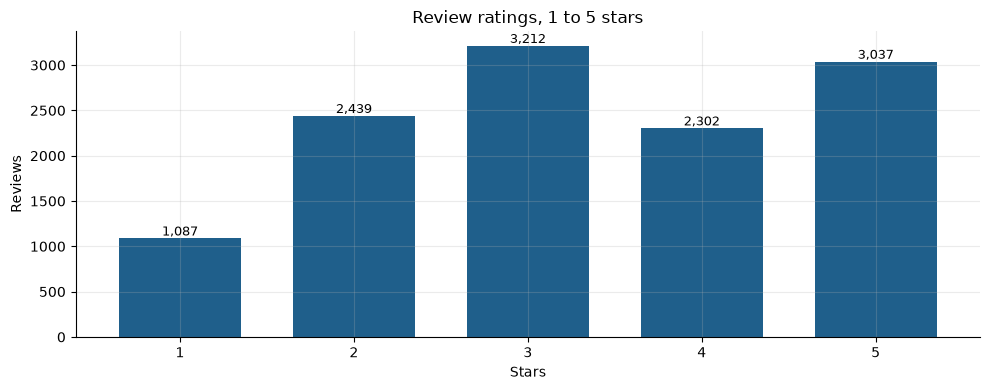

Mean rating: 3.312


In [3]:
counts = reviews["rating"].value_counts().sort_index()

ax = counts.plot(kind="bar", color="#1f5f8b", width=0.7)
ax.set_title("Review ratings, 1 to 5 stars")
ax.set_xlabel("Stars")
ax.set_ylabel("Reviews")
ax.set_xticklabels(["1", "2", "3", "4", "5"], rotation=0)
for position, value in enumerate(counts):
    ax.text(position, value + max(counts) * 0.01, format(value, ","), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

print("Mean rating:", round(reviews["rating"].mean(), 3))


## Which scenario produced which rating

Every rating stays inside its scenario's declared band. The heatmap is the quickest check that the bands mean what they say.


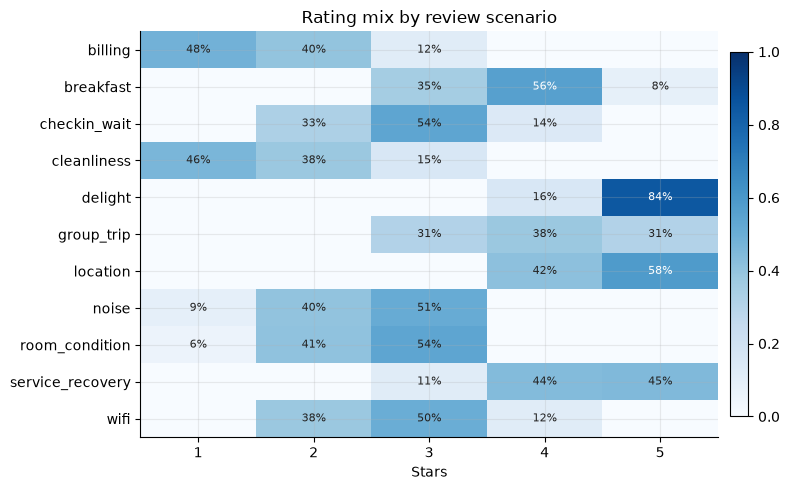

In [4]:
grid = pd.crosstab(reviews["scenario_id"], reviews["rating"])
share = grid.div(grid.sum(axis=1), axis=0).round(3)

figure, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(share.values, cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(5))
ax.set_xticklabels(["1", "2", "3", "4", "5"])
ax.set_yticks(range(len(share)))
ax.set_yticklabels(share.index)
ax.set_xlabel("Stars")
ax.set_title("Rating mix by review scenario")
for row in range(share.shape[0]):
    for column in range(share.shape[1]):
        value = share.values[row, column]
        if value > 0.01:
            ax.text(column, row, "{:.0%}".format(value), ha="center", va="center",
                    color="white" if value > 0.55 else "#222222", fontsize=8)
figure.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
plt.tight_layout()
plt.show()


## Sentiment against stars

The lexicon is fixed and boundary safe. It is still noisy on purpose: a three star review can read neutral, and a five star review can carry one complaint.


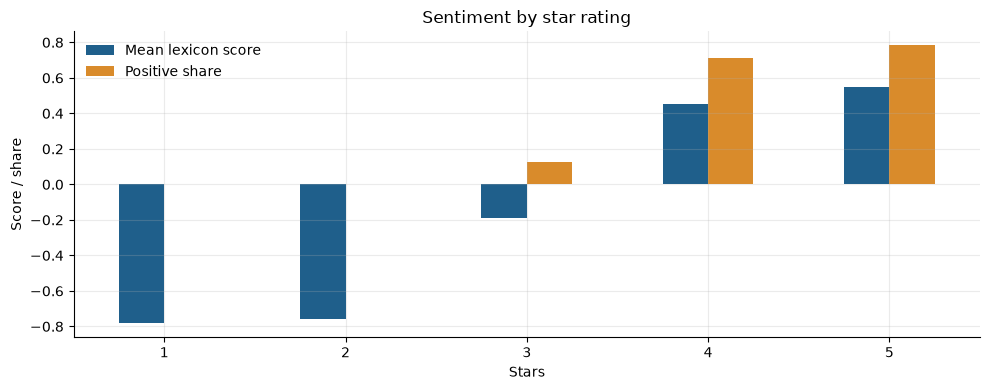

,mean_score,positive_share
rating,,
1,-0.781,0.000
2,-0.758,0.000
3,-0.191,0.124
4,0.455,0.710
5,0.550,0.784


In [5]:
summary = reviews.groupby("rating").agg(
    mean_score=("sentiment_score", "mean"),
    positive_share=("sentiment", lambda s: (s == "positive").mean()),
).round(3)

ax = summary[["mean_score", "positive_share"]].plot(kind="bar", color=["#1f5f8b", "#d98b2b"])
ax.set_title("Sentiment by star rating")
ax.set_xlabel("Stars")
ax.set_ylabel("Score / share")
ax.set_xticklabels(["1", "2", "3", "4", "5"], rotation=0)
ax.legend(["Mean lexicon score", "Positive share"], frameon=False)
plt.tight_layout()
plt.show()

summary


## Return intent and the response

Low-star reviews are answered more often and faster, as a service recovery queue would.


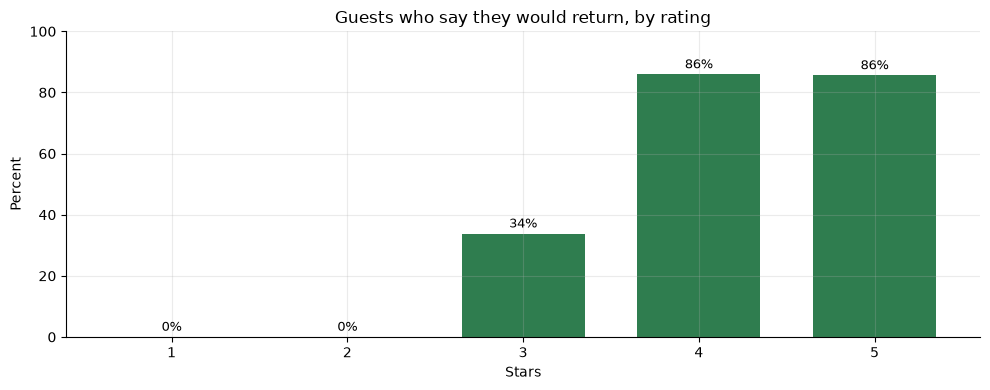

In [6]:
return_rate = (reviews.groupby("rating")["would_return"].mean() * 100).round(1)

ax = return_rate.plot(kind="bar", color="#2f7d4f", width=0.7)
ax.set_title("Guests who say they would return, by rating")
ax.set_xlabel("Stars")
ax.set_ylabel("Percent")
ax.set_xticklabels(["1", "2", "3", "4", "5"], rotation=0)
ax.set_ylim(0, 100)
for position, value in enumerate(return_rate):
    ax.text(position, value + 2, "{:.0f}%".format(value), ha="center", fontsize=9)
plt.tight_layout()
plt.show()


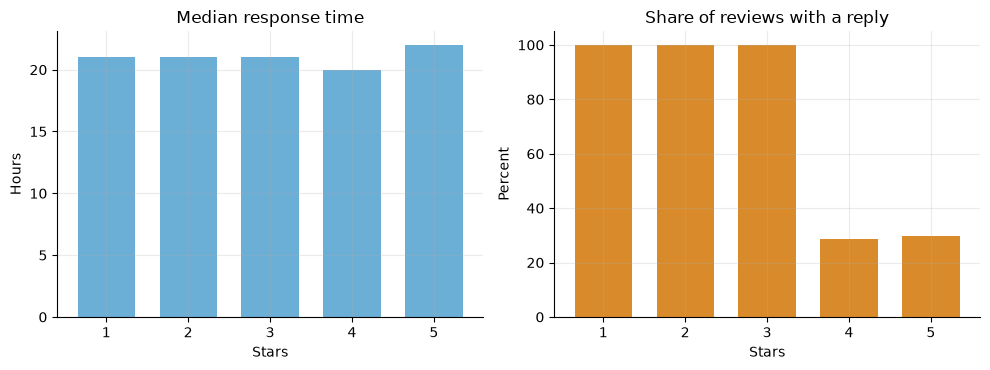

In [7]:
replied = reviews.dropna(subset=["response_hours"])
median_hours = replied.groupby("rating")["response_hours"].median()
response_rate = (reviews.assign(replied=reviews["response_text"].str.len() > 0)
                 .groupby("rating")["replied"].mean() * 100).round(1)

figure, axes = plt.subplots(1, 2, figsize=(10, 3.8))
median_hours.plot(kind="bar", ax=axes[0], color="#6baed6", width=0.7)
axes[0].set_title("Median response time")
axes[0].set_xlabel("Stars")
axes[0].set_ylabel("Hours")
axes[0].set_xticklabels(["1", "2", "3", "4", "5"], rotation=0)
response_rate.plot(kind="bar", ax=axes[1], color="#d98b2b", width=0.7)
axes[1].set_title("Share of reviews with a reply")
axes[1].set_xlabel("Stars")
axes[1].set_ylabel("Percent")
axes[1].set_xticklabels(["1", "2", "3", "4", "5"], rotation=0)
plt.tight_layout()
plt.show()


## Value is the bridge to the market panel

The value subscore is the one that moves with the rate position, so it is the natural join between the review feed and the pricing data.


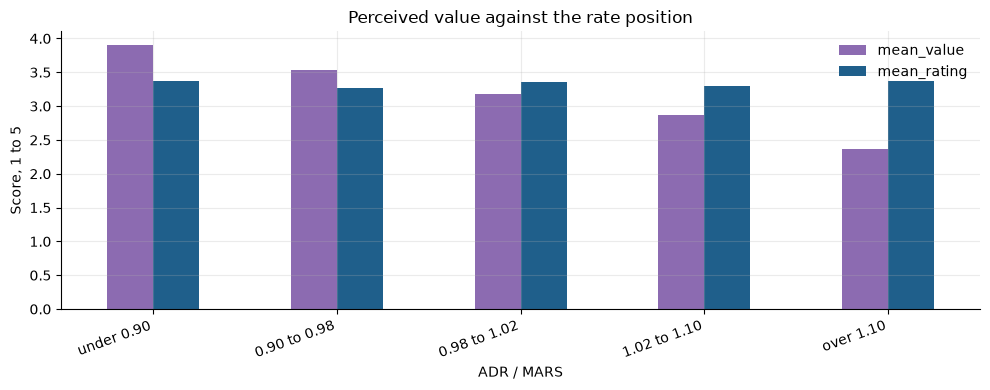

,mean_value,mean_rating,reviews
position_band,,,
under 0.90,3.91,3.37,566
0.90 to 0.98,3.54,3.27,3673
0.98 to 1.02,3.18,3.35,2801
1.02 to 1.10,2.87,3.29,3674
over 1.10,2.37,3.37,1363


In [8]:
reviews["position_band"] = pd.cut(
    reviews["rate_position"],
    bins=[0, 0.90, 0.98, 1.02, 1.10, 2.0],
    labels=["under 0.90", "0.90 to 0.98", "0.98 to 1.02", "1.02 to 1.10", "over 1.10"],
)
value = reviews.groupby("position_band", observed=True).agg(
    mean_value=("value_score", "mean"),
    mean_rating=("rating", "mean"),
    reviews=("review_id", "count"),
).round(2)

ax = value[["mean_value", "mean_rating"]].plot(kind="bar", color=["#8c6bb1", "#1f5f8b"])
ax.set_title("Perceived value against the rate position")
ax.set_xlabel("ADR / MARS")
ax.set_ylabel("Score, 1 to 5")
ax.set_xticklabels(value.index, rotation=20, ha="right")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

value


## What low-star reviews are about

The scenario counts give a complaint taxonomy without reading free text.


In [9]:
low = reviews[reviews["rating"] <= 2]
themes = (low.groupby("scenario_id").size().sort_values(ascending=False).to_frame("low_star_reviews"))
themes["share_of_low"] = (themes["low_star_reviews"] / len(low)).round(3)
themes["mean_rating"] = low.groupby("scenario_id")["rating"].mean().round(2)
themes


,low_star_reviews,share_of_low,mean_rating
scenario_id,,,
billing,909,0.258,1.45
cleanliness,735,0.208,1.45
room_condition,648,0.184,1.88
noise,613,0.174,1.82
checkin_wait,330,0.094,2.00
wifi,291,0.083,2.00


Read the feed as a cause and an effect: the scenario states what happened, the stars state how
the guest scored it, and the subscores state which part of the stay moved. The value score is the
one that tracks the rate position, which is why the last table is the useful join between this
notebook and the market panel.